## Семинар 11: Мультимодальные модели

План: запускаем модели и смотрим на тонкие места, о которых говорили на лекции.

- **CLIP**: zero-shot классификация; что модель видит после препроцессинга; зачем нужна температура.
- **BLIP**: ITC и ITM на одних и тех же подписях; генерация подписи.
- **LLaVA**: VQA; сколько визуальных токенов получает LLM.

Картинка: «extreme ironing» из статьи LLaVA, тот же пример, что на лекции сравнивали с GPT-4.

Нужна GPU (Colab T4 хватает): LLaVA-1.5-7B в fp16 занимает около 14 ГБ.
Все модели загружаются через 🤗 Transformers.

In [1]:
# !pip install -U transformers accelerate   # нужен transformers >= 4.56 (аргумент dtype)
import gc
import warnings
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from PIL import Image
from transformers import (
    AutoProcessor,
    BlipForConditionalGeneration,
    BlipForImageTextRetrieval,
    BlipProcessor,
    CLIPModel,
    CLIPProcessor,
    LlavaForConditionalGeneration,
)

warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32


def load_image(url):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    r.raise_for_status()
    return Image.open(BytesIO(r.content)).convert("RGB")


def to_image(pixel_values, mean, std):
    # Обратная нормализация: тензор (3, H, W) -> картинка, которую получает модель
    x = pixel_values.float().cpu() * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im)
        ax.set_title(t)
        ax.axis("off")
    plt.show()

(570, 380)


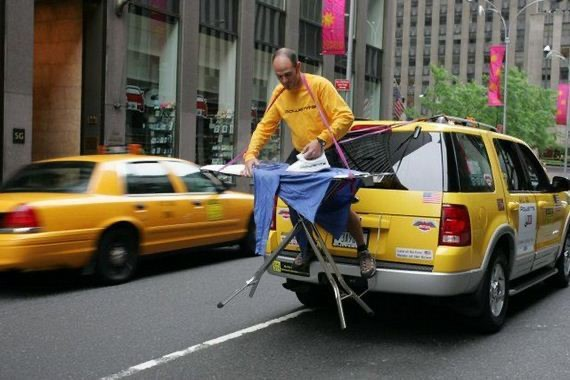

In [2]:
url = "https://raw.githubusercontent.com/haotian-liu/LLaVA/main/llava/serve/examples/extreme_ironing.jpg"
image = load_image(url)
print(image.size)
image

### CLIP — zero-shot классификация

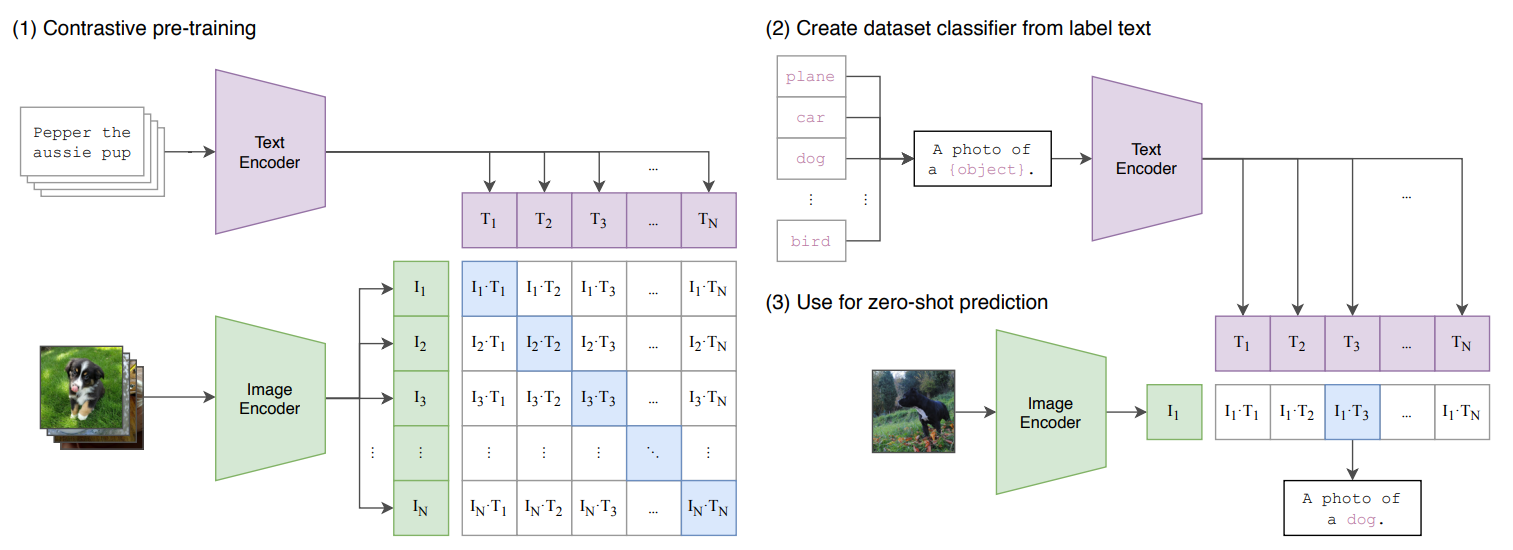

In [3]:
clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to(device).eval()
clip_processor = CLIPProcessor.from_pretrained(clip_id)

labels = [
    "a photo of a taxi",
    "a photo of a man ironing clothes",
    "a photo of a man ironing clothes on the back of a taxi",
    "a photo of a city street",
    "a photo of a dog",
]
inputs = clip_processor(text=labels, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    out = clip_model(**inputs)

probs = out.logits_per_image.softmax(dim=-1)[0]
for label, p in zip(labels, probs):
    print(f"{p:.3f}  {label}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

0.003  a photo of a taxi
0.000  a photo of a man ironing clothes
0.996  a photo of a man ironing clothes on the back of a taxi
0.000  a photo of a city street
0.000  a photo of a dog


#### Что на самом деле видит CLIP

Процессор уменьшает картинку по короткой стороне до 224, вырезает центр 224×224 и нормализует по mean/std.
Края широкой картинки модель не видит. ViT-B/32 режет вход на (224/32)² = 49 патчей, плюс CLS.

pixel_values: (1, 3, 224, 224)


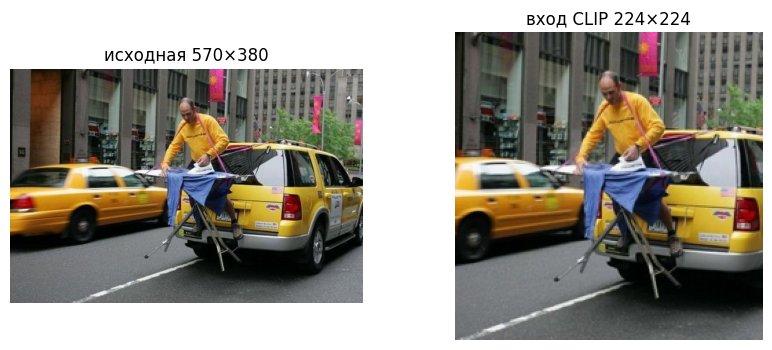

In [5]:
ip = clip_processor.image_processor
print("pixel_values:", tuple(inputs["pixel_values"].shape))
show([image, to_image(inputs["pixel_values"][0], ip.image_mean, ip.image_std)],
     [f"исходная {image.size[0]}×{image.size[1]}", "вход CLIP 224×224"])

#### Температура

Логиты = exp(t) · cos. Эмбеддинги L2-нормированы, поэтому cos ∈ [−1, 1].
Сравним softmax по «сырым» косинусам и после умножения на exp(t).

In [4]:
cos = (out.text_embeds @ out.image_embeds.T).squeeze()
scale = clip_model.logit_scale.exp().item()
print(f"exp(t) = {scale:.1f}")  # при обучении дошло до потолка 100
print("cos:                ", cos.cpu().numpy().round(3))
print("softmax(cos):       ", cos.softmax(0).cpu().numpy().round(3))
print("softmax(exp(t)·cos):", (scale * cos).softmax(0).cpu().numpy().round(3))

exp(t) = 100.0
cos:                 [0.29  0.262 0.347 0.213 0.189]
softmax(cos):        [0.206 0.2   0.218 0.191 0.186]
softmax(exp(t)·cos): [0.003 0.    0.996 0.    0.   ]


### BLIP — image-text matching и генерация кэпшенов

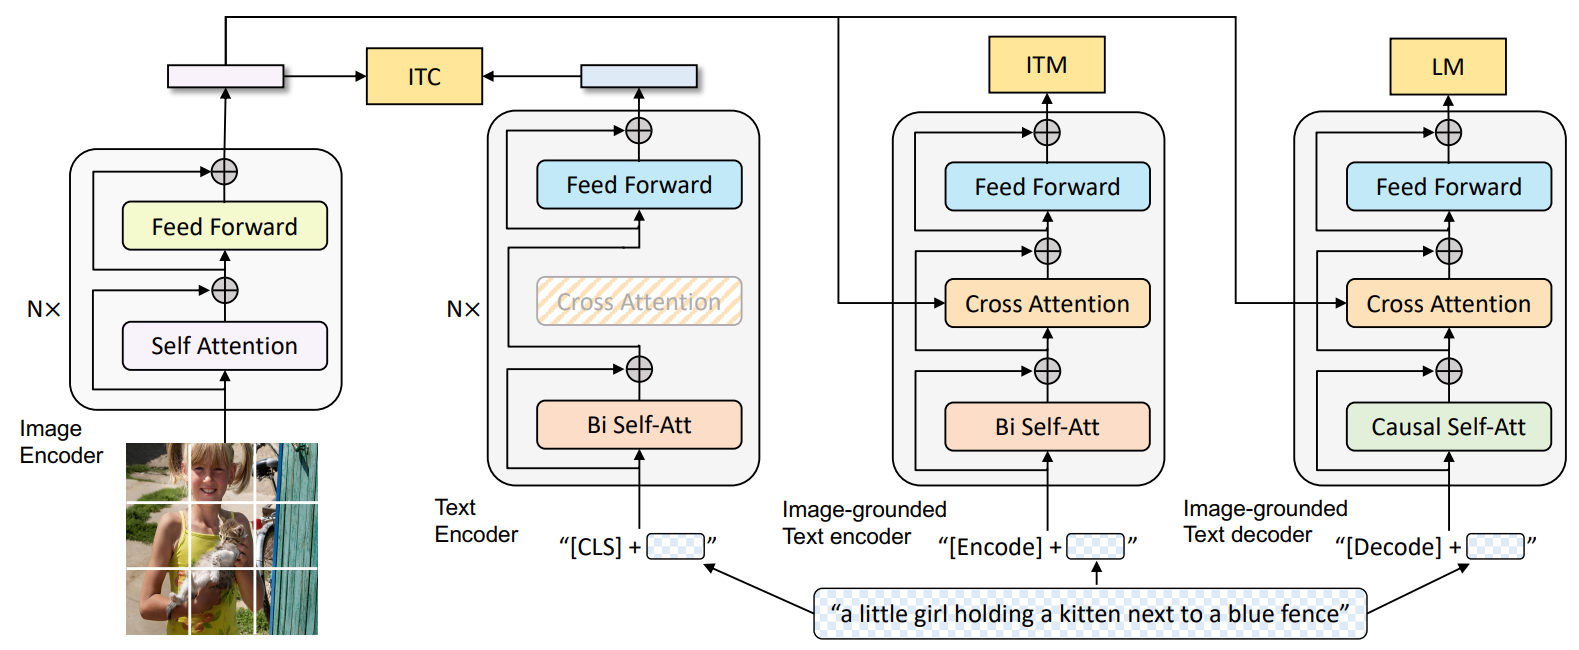

#### ITC и ITM на одних и тех же подписях

- **ITC**: косинус между эмбеддингами из отдельных энкодеров. Быстро, годится для поиска по базе.
- **ITM**: классификатор «подходит / не подходит», текст смотрит на патчи через cross-attention. Медленно, используется для переранжирования.

Подписи отличаются деталями: где стоит человек, цвет рубашки, действие.

In [6]:
itm_id = "Salesforce/blip-itm-base-coco"
itm_processor = BlipProcessor.from_pretrained(itm_id)
itm_model = BlipForImageTextRetrieval.from_pretrained(itm_id).to(device).eval()

texts = [
    "a man ironing clothes on the back of a yellow taxi",
    "a man ironing clothes on the roof of a yellow taxi",
    "a man ironing clothes next to a yellow taxi",
    "a man in a blue shirt ironing on a taxi",
    "a man washing a yellow taxi",
    "a yellow taxi on a city street",
    "a woman ironing clothes at home",
]

print("ITC cos   ITM p(match)   ITM логит   текст")
for text in texts:
    inputs = itm_processor(images=image, text=text, return_tensors="pt").to(device)
    with torch.no_grad():
        itc = itm_model(**inputs, use_itm_head=False).itm_score.item()
        itm = itm_model(**inputs).itm_score[0]  # логиты [не подходит, подходит]
    print(f"{itc:7.3f}   {itm.softmax(-1)[1]:12.3f}   {itm[1] - itm[0]:9.2f}   {text}")

preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/456 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (3 outputs left out)

ITC cos   ITM p(match)   ITM логит   текст
  0.534          1.000        9.85   a man ironing clothes on the back of a yellow taxi
  0.520          1.000        9.80   a man ironing clothes on the roof of a yellow taxi
  0.505          1.000        9.67   a man ironing clothes next to a yellow taxi


model.safetensors: reconstructing file:   0%|          |  0.00B /  895MB            

model.safetensors: downloading bytes:           |  0.00B            

  0.476          0.999        6.91   a man in a blue shirt ironing on a taxi
  0.436          0.996        5.45   a man washing a yellow taxi
  0.411          0.343       -0.65   a yellow taxi on a city street
  0.271          0.000       -9.71   a woman ironing clothes at home


На что посмотреть:

- обе оценки ставят первой верную подпись;
- «on the back / on the roof / next to» почти не различаются: пространственные отношения — слабое место таких моделей
  ([Yuksekgonul et al., ICLR 2023](https://arxiv.org/abs/2210.01936): модели ведут себя как «мешок слов»);
- ITM почти уверенно принимает ложное «washing a yellow taxi», но отвергает верное, но неполное «a yellow taxi on a city street»:
  на hard negatives модель училась отличать полные подписи от почти полных.

In [7]:
cap_id = "Salesforce/blip-image-captioning-base"
cap_processor = BlipProcessor.from_pretrained(cap_id)
cap_model = BlipForConditionalGeneration.from_pretrained(cap_id).to(device).eval()

# Без префикса и с префиксом: декодер продолжает заданное начало подписи
for prefix in [None, "a photo of", "this is unusual because"]:
    inputs = cap_processor(image, text=prefix, return_tensors="pt").to(device)
    with torch.no_grad():
        out = cap_model.generate(**inputs, max_new_tokens=30)
    print(f"{str(prefix):>24} -> {cap_processor.decode(out[0], skip_special_tokens=True)}")

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

                    None -> a man sitting on the back of a car
              a photo of -> a photo of a man sitting on the back of a car
 this is unusual because -> this is unusual because it ' s a car


### LLaVA — Visual Question Answering

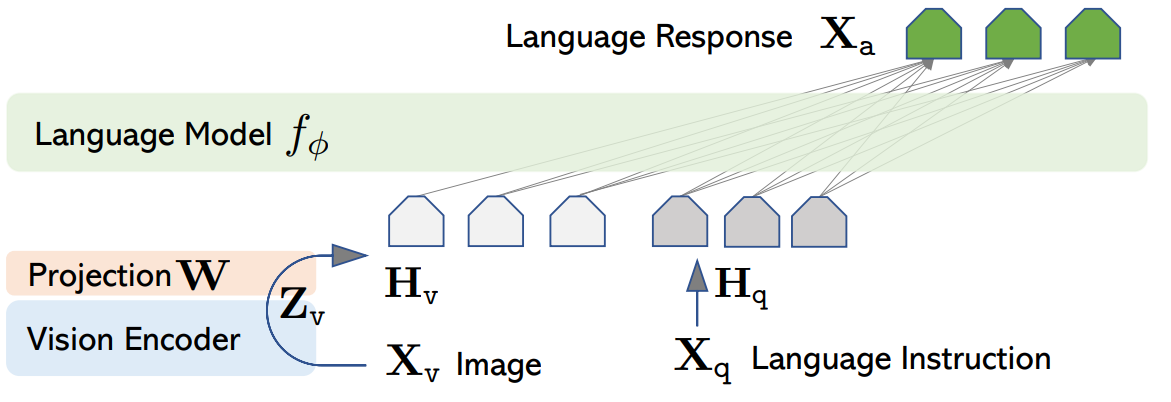

#### Сколько токенов получает LLM

CLIP ViT-L/14 на 336×336 дает (336/14)² = 576 патч-токенов. CLS не используется.
Процессор раскрывает один `<image>` в промпте в 576 токенов.
HF-процессор LLaVA-1.5 вырезает центр, а в оригинальном LLaVA-1.5 картинку дополняли до квадрата (pad).

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.45k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

pixel_values: (1, 3, 336, 336)
токенов <image>: 576
длина input_ids: 589


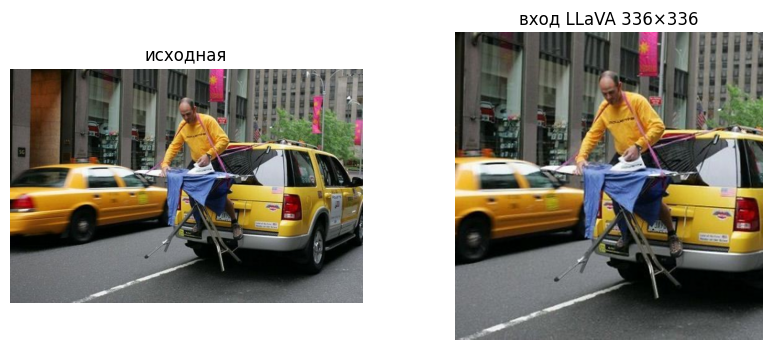

In [8]:
llava_id = "llava-hf/llava-1.5-7b-hf"
llava_processor = AutoProcessor.from_pretrained(llava_id)

inputs = llava_processor(images=image, text="USER: <image>\nHi ASSISTANT:", return_tensors="pt")
image_token = llava_processor.tokenizer.convert_tokens_to_ids("<image>")
print("pixel_values:", tuple(inputs["pixel_values"].shape))
print("токенов <image>:", (inputs["input_ids"] == image_token).sum().item())
print("длина input_ids:", inputs["input_ids"].shape[1])

ip = llava_processor.image_processor
show([image, to_image(inputs["pixel_values"][0], ip.image_mean, ip.image_std)],
     ["исходная", "вход LLaVA 336×336"])

In [ ]:
# LLaVA-7B в fp16 занимает ~13 ГиБ, на T4 всего 15 ГиБ: сначала выгружаем CLIP и BLIP
for name in ["clip_model", "itm_model", "cap_model"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

llava = LlavaForConditionalGeneration.from_pretrained(llava_id, dtype=dtype, device_map="auto")
if device == "cuda":
    print(f"GPU занято: {torch.cuda.memory_allocated() / 2**30:.1f} ГиБ")


def ask_llava(question, max_new_tokens=80):
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = llava_processor(images=image, text=prompt, return_tensors="pt").to(llava.device, dtype)
    with torch.no_grad():
        out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return llava_processor.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


questions = [
    "What is unusual about this image?",
    "How many taxis are in the image?",
    "Where exactly is the ironing board attached to the car?",
    "What is the license plate number of the taxi?",  # номера не читаются: проверка на галлюцинации
]
for q in questions:
    print("Q:", q)
    print("A:", ask_llava(q), "\n")

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

### Вопросы для обсуждения

1. Почему softmax по «сырым» косинусам CLIP почти равномерный и что меняет exp(t)?
   <details><summary>Ответ</summary>cos ∈ [−1, 1], разности логитов малы. exp(t) ≈ 100 растягивает их, и softmax становится острым; без этого лосс почти не учится.</details>
2. Что CLIP и LLaVA теряют из-за center crop? Как это решает LLaVA-NeXT?
   <details><summary>Ответ</summary>Объекты у краев широкой картинки. LLaVA-NeXT (AnyRes) режет картинку на фрагменты плюс уменьшенная копия.</details>
3. Почему ITC почти не различает «on the back / next to a taxi»? Должен ли ITM различать лучше?
   <details><summary>Ответ</summary>ITC сравнивает один вектор картинки с одним вектором текста, токены не взаимодействуют. ITM смотрит на патчи через cross-attention и в принципе может различать, но на этих подписях тоже не различает: отношения плохо представлены в данных.</details>
4. Почему модель может уверенно назвать номер такси, который на картинке не читается?
   <details><summary>Ответ</summary>Галлюцинация: LLM продолжает правдоподобный текст по своим априорным знаниям, а визуальных деталей при низком разрешении не хватает. Отказ «не видно» надо отдельно учить.</details>